In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = Path("mpmc_cardpaymentsbymerchantcategory.csv")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE.resolve()}. "
        "Check the CSV filename and make sure it is beside this notebook."
    )

df = pd.read_csv(DATA_FILE, low_memory=False)

print(f"Original dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Original dataset: 305,514 rows × 21 columns


,REPORTINGPERIOD,SERIES_KEY,OBSERVATION,CONFIDENTIALITY_FLAG,UNITS,FREQ,FREQ_DESC,REF_AREA,REF_AREA_DESC,COUNT_AREA,...,TRMNL_LCTN,TRMNL_LCTN_DESC,RMT_INTTN,RMT_INTTN_DESC,MRCHNT_CTGRY_CD,MRCHNT_CTGRY_CD_DESC,TRANSFORMATION,TRANSFORMATION_DESC,UNIT_MEASURE,UNIT_MEASURE_DESC
0,2026-08-31,PMC.M.IE._Z.W0._T.0742.N.EUR,24540792.52,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0742,Veterinary services,N,Non transformed data,EUR,Euro
1,2026-08-31,PMC.M.IE._Z.W0._T.0742.N.PN,251796.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0742,Veterinary services,N,Non transformed data,PN,Pure number
2,2026-08-31,PMC.M.IE._Z.W0._T.0743.N.EUR,0.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0743,Wine producers,N,Non transformed data,EUR,Euro
3,2026-08-31,PMC.M.IE._Z.W0._T.0743.N.PN,0.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0743,Wine producers,N,Non transformed data,PN,Pure number
4,2026-08-31,PMC.M.IE._Z.W0._T.0744.N.EUR,0.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0744,Champagne producers,N,Non transformed data,EUR,Euro


In [2]:
#inspect columns and data types
print("Dataset shape:", df.shape)

display(df.dtypes.to_frame("Data type"))

display(df.head())

Dataset shape: (305514, 21)


,Data type
REPORTINGPERIOD,object
SERIES_KEY,object
OBSERVATION,float64
CONFIDENTIALITY_FLAG,object
UNITS,object
FREQ,object
FREQ_DESC,object
REF_AREA,object
REF_AREA_DESC,object
COUNT_AREA,object


,REPORTINGPERIOD,SERIES_KEY,OBSERVATION,CONFIDENTIALITY_FLAG,UNITS,FREQ,FREQ_DESC,REF_AREA,REF_AREA_DESC,COUNT_AREA,...,TRMNL_LCTN,TRMNL_LCTN_DESC,RMT_INTTN,RMT_INTTN_DESC,MRCHNT_CTGRY_CD,MRCHNT_CTGRY_CD_DESC,TRANSFORMATION,TRANSFORMATION_DESC,UNIT_MEASURE,UNIT_MEASURE_DESC
0,2026-08-31,PMC.M.IE._Z.W0._T.0742.N.EUR,24540792.52,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0742,Veterinary services,N,Non transformed data,EUR,Euro
1,2026-08-31,PMC.M.IE._Z.W0._T.0742.N.PN,251796.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0742,Veterinary services,N,Non transformed data,PN,Pure number
2,2026-08-31,PMC.M.IE._Z.W0._T.0743.N.EUR,0.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0743,Wine producers,N,Non transformed data,EUR,Euro
3,2026-08-31,PMC.M.IE._Z.W0._T.0743.N.PN,0.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0743,Wine producers,N,Non transformed data,PN,Pure number
4,2026-08-31,PMC.M.IE._Z.W0._T.0744.N.EUR,0.00,F,Exact Amount,M,Monthly,IE,Ireland,_Z,...,W0,"World (all entities, including reference area,...",_T,Initiated either via remote or non-remote channel,0744,Champagne producers,N,Non transformed data,EUR,Euro


In [3]:
#Check for missing values and duplicates
print("Missing values by column:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing values")
)

print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate series and reporting-date pairs:",
    df.duplicated(
        subset=["SERIES_KEY", "REPORTINGPERIOD"]
    ).sum()
)

Missing values by column:


,Missing values
OBSERVATION,21451
REPORTINGPERIOD,0
TRMNL_LCTN,0
UNIT_MEASURE,0
TRANSFORMATION_DESC,0
TRANSFORMATION,0
MRCHNT_CTGRY_CD_DESC,0
MRCHNT_CTGRY_CD,0
RMT_INTTN_DESC,0
RMT_INTTN,0


Exact duplicate rows: 0
Duplicate series and reporting-date pairs: 0


In [4]:
#Examine confidentiality and measures
print("Confidentiality flags:")
display(
    df["CONFIDENTIALITY_FLAG"]
    .value_counts(dropna=False)
    .to_frame("Number of rows")
)

print("Measurement types:")
display(
    df["UNIT_MEASURE"]
    .value_counts(dropna=False)
    .to_frame("Number of rows")
)

print("Reporting period:")
print(
    df["REPORTINGPERIOD"].min(),
    "to",
    df["REPORTINGPERIOD"].max()
)

Confidentiality flags:


,Number of rows
CONFIDENTIALITY_FLAG,
F,284063
C,21451


Measurement types:


,Number of rows
UNIT_MEASURE,
EUR,152757
PN,152757


Reporting period:
2022-10-31 to 2026-08-31


In [5]:
#Creating analysis dataset

reported_df = df.loc[
    df["CONFIDENTIALITY_FLAG"].eq("F")
    & df["OBSERVATION"].notna()
].copy()

reported_df["OBSERVATION"] = pd.to_numeric(
    reported_df["OBSERVATION"],
    errors="coerce"
)

reported_df = reported_df.dropna(
    subset=["OBSERVATION"]
)

print("All rows:", len(df))
print("Reported observations:", len(reported_df))

display(
    reported_df.groupby("UNIT_MEASURE")["OBSERVATION"]
    .describe()
    .round(2)
)

All rows: 305514
Reported observations: 284063


,count,mean,std,min,25%,50%,75%,max
UNIT_MEASURE,,,,,,,,
EUR,141122.0,33580128.75,1.985957e+08,0.0,72297.73,898587.12,6930635.67,5.184542e+09
PN,142941.0,851096.49,5.596999e+06,0.0,656.00,9851.00,117746.00,1.483896e+08


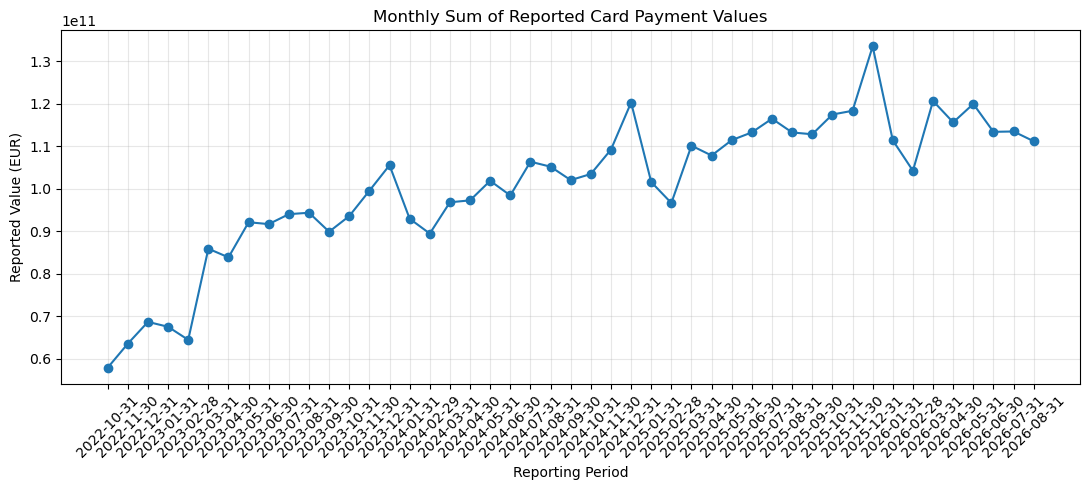

In [6]:
#Monthly trend in payment values
eur_df = reported_df.loc[
    reported_df["UNIT_MEASURE"].eq("EUR")
].copy()

monthly_eur = (
    eur_df.groupby("REPORTINGPERIOD")["OBSERVATION"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_eur.index,
    monthly_eur.values,
    marker="o"
)

plt.title("Monthly Sum of Reported Card Payment Values")
plt.xlabel("Reporting Period")
plt.ylabel("Reported Value (EUR)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

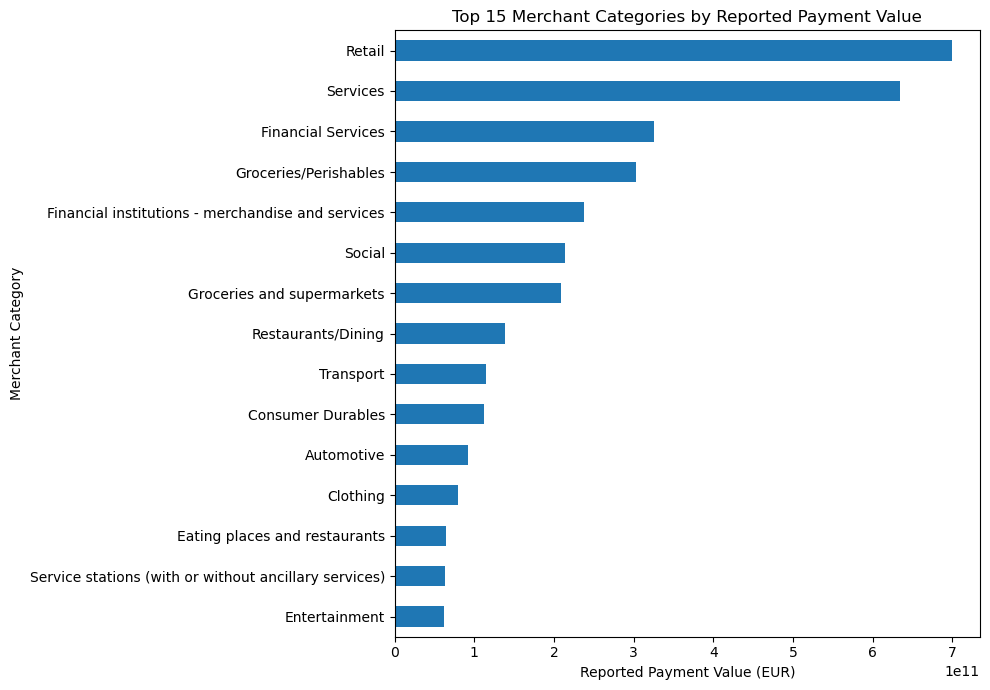

In [7]:
#Top 15 merchant categories by payment value
eur_category = (
    eur_df.groupby("MRCHNT_CTGRY_CD_DESC")["OBSERVATION"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
eur_category.plot(kind="barh")

plt.title("Top 15 Merchant Categories by Reported Payment Value")
plt.xlabel("Reported Payment Value (EUR)")
plt.ylabel("Merchant Category")
plt.tight_layout()
plt.show()

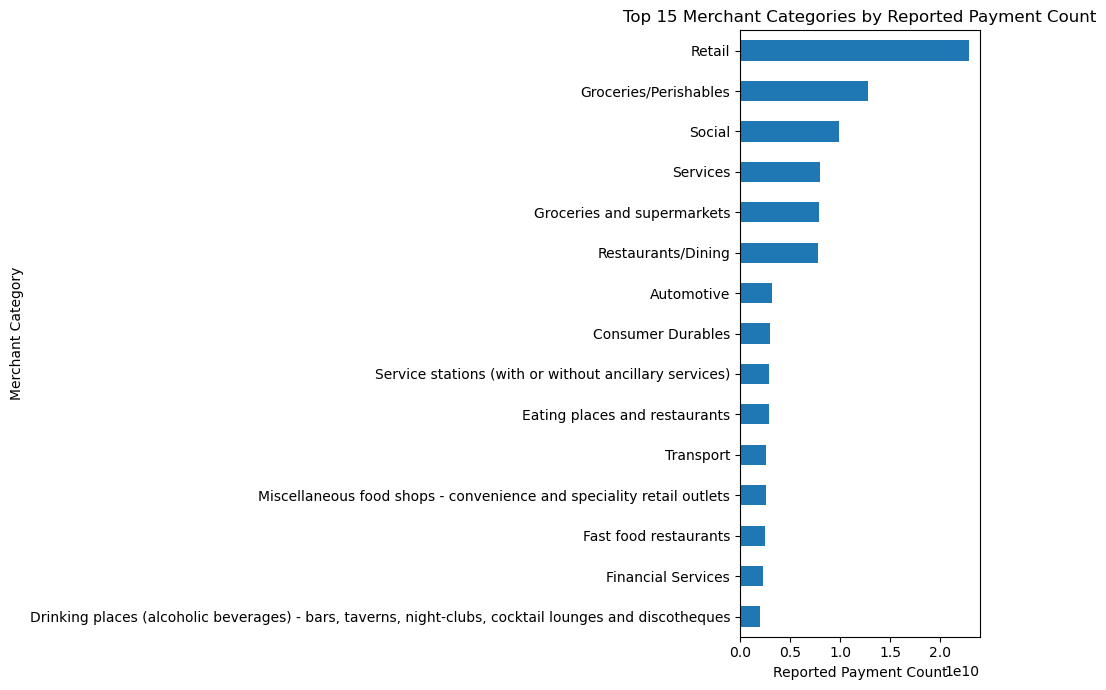

In [ ]:
#Top 15 merchant categories by payment count
pn_df = reported_df.loc[
    reported_df["UNIT_MEASURE"].eq("PN")
].copy()

pn_category = (
    pn_df.groupby("MRCHNT_CTGRY_CD_DESC")["OBSERVATION"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))
pn_category.plot(kind="barh")

plt.title("Top 15 Merchant Categories by Reported Payment Count")
plt.xlabel("Reported Payment Count")
plt.ylabel("Merchant Category")
plt.tight_layout()
plt.show()

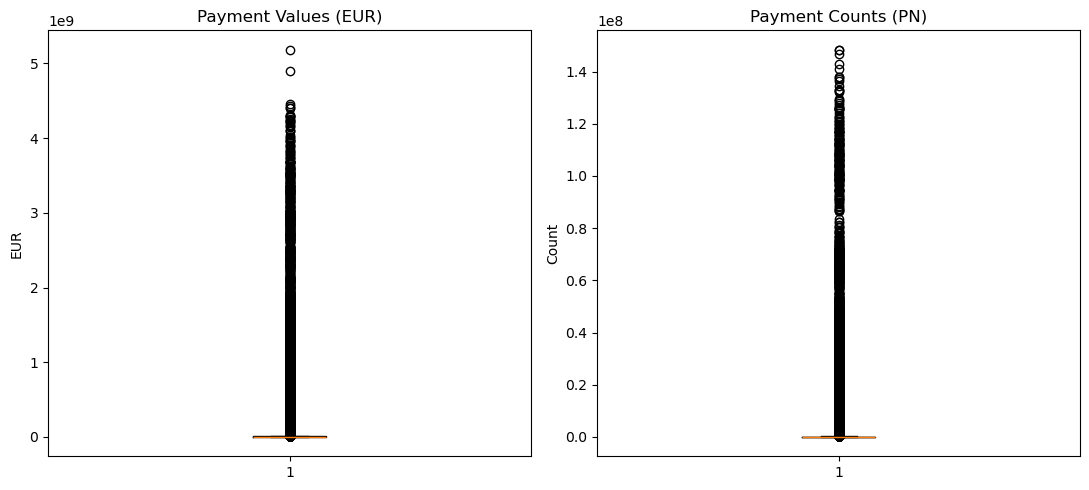

In [9]:
#Examining distribution and potential outliers
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].boxplot(eur_df["OBSERVATION"].dropna())
axes[0].set_title("Payment Values (EUR)")
axes[0].set_ylabel("EUR")

axes[1].boxplot(pn_df["OBSERVATION"].dropna())
axes[1].set_title("Payment Counts (PN)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

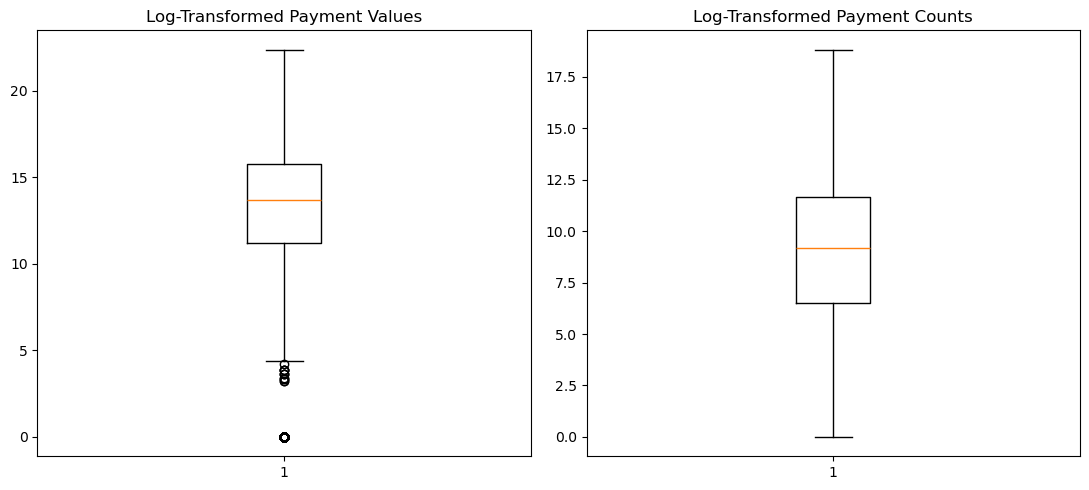

In [10]:
#View distributions using log transformations
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

eur_values = eur_df.loc[
    eur_df["OBSERVATION"] >= 0, "OBSERVATION"
]

pn_values = pn_df.loc[
    pn_df["OBSERVATION"] >= 0, "OBSERVATION"
]

axes[0].boxplot(np.log1p(eur_values))
axes[0].set_title("Log-Transformed Payment Values")

axes[1].boxplot(np.log1p(pn_values))
axes[1].set_title("Log-Transformed Payment Counts")

plt.tight_layout()
plt.show()

In [11]:
#Checking zero observations 
zero_summary = (
    reported_df.assign(
        IS_ZERO=reported_df["OBSERVATION"].eq(0)
    )
    .groupby("UNIT_MEASURE")["IS_ZERO"]
    .agg(["sum", "count"])
)

zero_summary["zero_percentage"] = (
    zero_summary["sum"] / zero_summary["count"] * 100
).round(2)

display(zero_summary)

,sum,count,zero_percentage
UNIT_MEASURE,,,
EUR,19450,141122,13.78
PN,19450,142941,13.61


In [12]:
#Save the processed data
output_file = "merchant_card_payments_processed.csv"

df.to_csv(output_file, index=False)

print("Processed dataset saved as:", output_file)

Processed dataset saved as: merchant_card_payments_processed.csv


In [13]:
# Feature Engineering and Modelling Preparation

model_df = reported_df.loc[
    reported_df["UNIT_MEASURE"].eq("EUR")
].copy()

# Sort by series and date
model_df = model_df.sort_values(
    ["SERIES_KEY", "REPORTINGPERIOD"]
).copy()

# Calendar features
model_df["REPORTINGPERIOD"] = pd.to_datetime(model_df["REPORTINGPERIOD"])
model_df["YEAR"] = model_df["REPORTINGPERIOD"].dt.year
model_df["MONTH"] = model_df["REPORTINGPERIOD"].dt.month

# Previous reported observations within each series
model_df["LAG_1"] = (
    model_df.groupby("SERIES_KEY")["OBSERVATION"].shift(1)
)

model_df["LAG_2"] = (
    model_df.groupby("SERIES_KEY")["OBSERVATION"].shift(2)
)

# Match the value from the actual next calendar month
future_df = model_df[
    ["SERIES_KEY", "REPORTINGPERIOD", "OBSERVATION"]
].copy()

future_df["REPORTINGPERIOD"] = (
    future_df["REPORTINGPERIOD"] - pd.DateOffset(months=1)
)

future_df = future_df.rename(
    columns={"OBSERVATION": "TARGET_NEXT_VALUE"}
)

model_df = model_df.merge(
    future_df,
    on=["SERIES_KEY", "REPORTINGPERIOD"],
    how="left",
    validate="one_to_one"
)

# Keep rows with all required values
model_ready_df = model_df.dropna(
    subset=["LAG_1", "LAG_2", "TARGET_NEXT_VALUE"]
).copy()

print("EUR rows available:", len(model_df))
print("Rows ready for modelling:", len(model_ready_df))

display(
    model_ready_df[
        [
            "SERIES_KEY",
            "REPORTINGPERIOD",
            "OBSERVATION",
            "LAG_1",
            "LAG_2",
            "TARGET_NEXT_VALUE"
        ]
    ].head(10)
)

EUR rows available: 141122
Rows ready for modelling: 76130


,SERIES_KEY,REPORTINGPERIOD,OBSERVATION,LAG_1,LAG_2,TARGET_NEXT_VALUE
2,PMC.M.IE._Z.W0.NR.0742.N.EUR,2022-12-31,17618367.66,19238222.62,17315954.25,18152565.81
4,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-02-28,17115352.26,18152565.81,17618367.66,20676963.56
6,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-04-30,19499723.70,20676963.56,17115352.26,22618413.51
8,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-06-30,22183843.66,22618413.51,19499723.70,22416782.45
9,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-07-31,22416782.45,22183843.66,22618413.51,22977545.76
11,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-09-30,21344774.13,22977545.76,22416782.45,21649666.92
13,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-11-30,22800073.23,21649666.92,21344774.13,21139427.01
14,PMC.M.IE._Z.W0.NR.0742.N.EUR,2023-12-31,21139427.01,22800073.23,21649666.92,22302184.78
16,PMC.M.IE._Z.W0.NR.0742.N.EUR,2024-02-29,21727616.59,22302184.78,21139427.01,20958959.61
18,PMC.M.IE._Z.W0.NR.0742.N.EUR,2024-04-30,18858191.06,20958959.61,21727616.59,19798626.27


In [ ]:
# Check whether consecutive rows represent consecutive months

month_gaps = (
    model_df.groupby("SERIES_KEY")["REPORTINGPERIOD"]
    .diff()
    .dt.days
)

print("Days between observations:")
display(month_gaps.describe())

print("\nGap lengths (days):")
display(month_gaps.value_counts().sort_index().head(15))

Days between observations:


count    137893.000000
mean         31.960179
std          15.643933
min          28.000000
25%          30.000000
50%          31.000000
75%          31.000000
max        1249.000000
Name: REPORTINGPERIOD, dtype: float64


Gap lengths (days):


REPORTINGPERIOD
28.0      7873
29.0      3017
30.0     44672
31.0     78944
59.0       536
60.0        69
61.0       956
62.0       327
89.0        33
90.0       478
91.0        98
92.0       228
120.0       70
121.0      126
122.0       62
Name: count, dtype: int64

In [15]:
# Check whether each observation is from the immediately following month

model_df = model_df.sort_values(
    ["SERIES_KEY", "REPORTINGPERIOD"]
).copy()

model_df["PREVIOUS_MONTH"] = (
    model_df.groupby("SERIES_KEY")["REPORTINGPERIOD"].shift(1)
)

model_df["MONTH_GAP"] = (
    (model_df["REPORTINGPERIOD"].dt.year
     - model_df["PREVIOUS_MONTH"].dt.year) * 12
    + model_df["REPORTINGPERIOD"].dt.month
    - model_df["PREVIOUS_MONTH"].dt.month
)

print("Month gap summary:")
display(model_df["MONTH_GAP"].value_counts(dropna=False).sort_index())

print("\nRows with a gap greater than one month:")
display(
    model_df.loc[
        model_df["MONTH_GAP"] > 1,
        ["SERIES_KEY", "PREVIOUS_MONTH", "REPORTINGPERIOD", "MONTH_GAP"]
    ].head(10)
)

Month gap summary:


MONTH_GAP
1.0     134506
2.0       1888
3.0        837
4.0        306
5.0        167
6.0         52
7.0         42
8.0         29
9.0          8
10.0        10
11.0         2
12.0         8
13.0         4
14.0         8
15.0         5
16.0         5
18.0         1
19.0         1
20.0         2
24.0         1
30.0         2
33.0         4
40.0         3
41.0         2
NaN       3229
Name: count, dtype: int64


Rows with a gap greater than one month:


,SERIES_KEY,PREVIOUS_MONTH,REPORTINGPERIOD,MONTH_GAP
142,PMC.M.IE._Z.W0.NR.0763.N.EUR,2022-10-31,2022-12-31,2.0
190,PMC.M.IE._Z.W0.NR.0780.N.EUR,2022-12-31,2023-02-28,2.0
378,PMC.M.IE._Z.W0.NR.1711.N.EUR,2023-01-31,2023-03-31,2.0
517,PMC.M.IE._Z.W0.NR.1750.N.EUR,2022-12-31,2023-03-31,3.0
560,PMC.M.IE._Z.W0.NR.1761.N.EUR,2022-12-31,2023-02-28,2.0
561,PMC.M.IE._Z.W0.NR.1761.N.EUR,2023-02-28,2023-04-30,2.0
562,PMC.M.IE._Z.W0.NR.1761.N.EUR,2023-04-30,2023-06-30,2.0
580,PMC.M.IE._Z.W0.NR.1761.N.EUR,2024-11-30,2025-01-31,2.0
610,PMC.M.IE._Z.W0.NR.1771.N.EUR,2023-11-30,2024-01-31,2.0
646,PMC.M.IE._Z.W0.NR.1799.N.EUR,2023-01-31,2023-03-31,2.0


In [16]:
#Regression and Feature preparation
print("Model-ready rows:", len(model_ready_df))
print("Missing values:")
display(model_ready_df[
    ["LAG_1", "LAG_2", "TARGET_NEXT_VALUE"]
].isna().sum())

print("Date range:")
print(model_ready_df["REPORTINGPERIOD"].min())
print(model_ready_df["REPORTINGPERIOD"].max())

Model-ready rows: 76130
Missing values:


LAG_1                0
LAG_2                0
TARGET_NEXT_VALUE    0
dtype: int64

Date range:
2022-12-31 00:00:00
2026-07-31 00:00:00


# Regression Modelling
#This section compares a baseline prediction,
#Linear Regression, and Random Forest Regression.

In [ ]:
#Train/Test split
# Sort the data by reporting date
model_ready_df = model_ready_df.sort_values(
    "REPORTINGPERIOD"
).copy()

# Choosing a cutoff based on unique dates (80% of dates)
dates = sorted(model_ready_df["REPORTINGPERIOD"].unique())
cutoff_index = int(len(dates) * 0.8)
cutoff_date = dates[cutoff_index]

# Training data  (December 2022 - September 2025)
train_df = model_ready_df[
    model_ready_df["REPORTINGPERIOD"] < cutoff_date
].copy()

# Test data (November 2025 - July 2026)
test_df = model_ready_df[
    model_ready_df["REPORTINGPERIOD"] >= cutoff_date
].copy()

# Features and target
features = ["LAG_1", "LAG_2", "YEAR", "MONTH"]
target = "TARGET_NEXT_VALUE"

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Cutoff date:", cutoff_date)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training date range:",
      train_df["REPORTINGPERIOD"].min(),
      "to",
      train_df["REPORTINGPERIOD"].max())
print("Testing date range:",
      test_df["REPORTINGPERIOD"].min(),
      "to",
      test_df["REPORTINGPERIOD"].max())

Cutoff date: 2025-11-30 00:00:00
Training rows: 57969
Testing rows: 18161
Training date range: 2022-12-31 00:00:00 to 2025-09-30 00:00:00
Testing date range: 2025-11-30 00:00:00 to 2026-07-31 00:00:00


In [18]:
# Check the target months in the training and test sets
train_target_months = (
    train_df["REPORTINGPERIOD"] + pd.DateOffset(months=1)
)

test_target_months = (
    test_df["REPORTINGPERIOD"] + pd.DateOffset(months=1)
)

print("Latest training target month:", train_target_months.max())
print("Earliest testing target month:", test_target_months.min())
print(
    "Target months overlap:",
    train_target_months.max() >= test_target_months.min()
)

Latest training target month: 2025-10-30 00:00:00
Earliest testing target month: 2025-12-30 00:00:00
Target months overlap: False


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Baseline to predict the mean target value from the training data
baseline_prediction = np.full(
    len(y_test),
    y_train.mean()
)

baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))
baseline_r2 = r2_score(y_test, baseline_prediction)

print("Baseline Regression Results")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R²:", round(baseline_r2, 4))

Baseline Regression Results
MAE: 58996759.74
RMSE: 231286803.85
R²: -0.0004


In [20]:
#Linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²:", round(linear_r2, 4))

Linear Regression Results
MAE: 4288350.69
RMSE: 27431245.13
R²: 0.9859


In [21]:
#Random Forest Regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 4))

Random Forest Regression Results
MAE: 3771758.34
RMSE: 25730316.51
R²: 0.9876


,Model,MAE,RMSE,R2
0,Baseline,5.899676e+07,2.312868e+08,-0.0004
1,Linear Regression,4.288351e+06,2.743125e+07,0.9859
2,Random Forest,3.771758e+06,2.573032e+07,0.9876


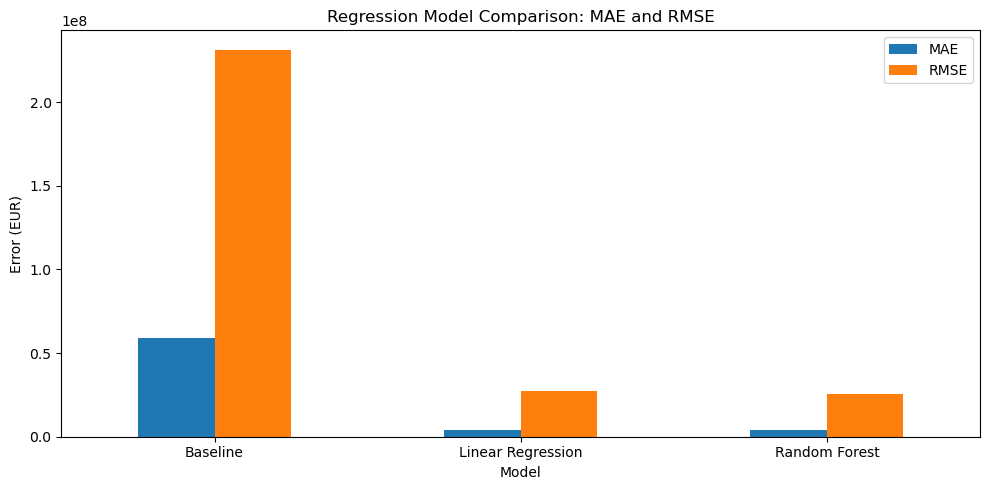

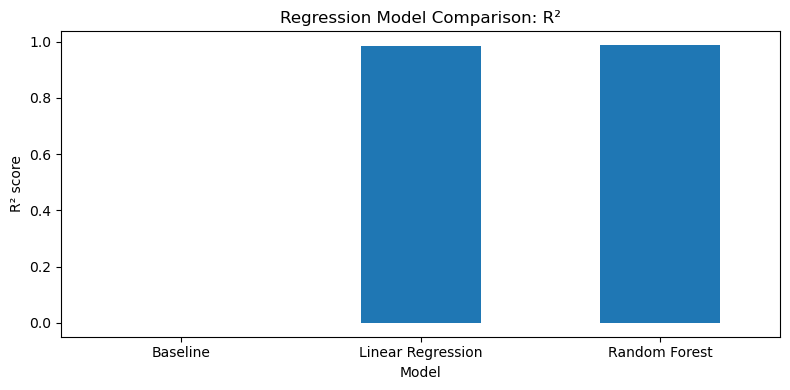

In [22]:
#Comparison chart
import pandas as pd
import matplotlib.pyplot as plt

results_df = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        rf_r2
    ]
})

display(results_df.round(4))

results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Regression Model Comparison: MAE and RMSE")
plt.ylabel("Error (EUR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

results_df.set_index("Model")["R2"].plot(
    kind="bar",
    figsize=(8, 4)
)
plt.title("Regression Model Comparison: R²")
plt.ylabel("R² score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Feature,Importance
0,LAG_1,0.940452
1,LAG_2,0.056208
3,MONTH,0.002639
2,YEAR,0.000702


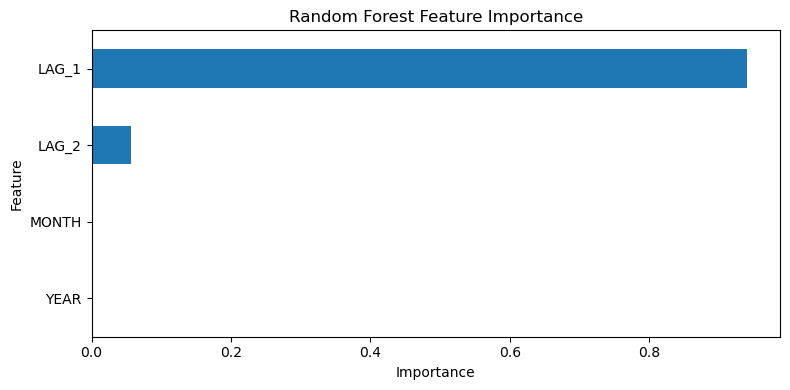

In [23]:
#Feature Importance
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

importance_df.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(8, 4)
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

,Feature,Importance,Std
0,LAG_1,6.450987e+07,155349.2420
1,LAG_2,2.537085e+06,12138.3451
3,MONTH,6.911058e+05,53074.6112
2,YEAR,-0.000000e+00,0.0000


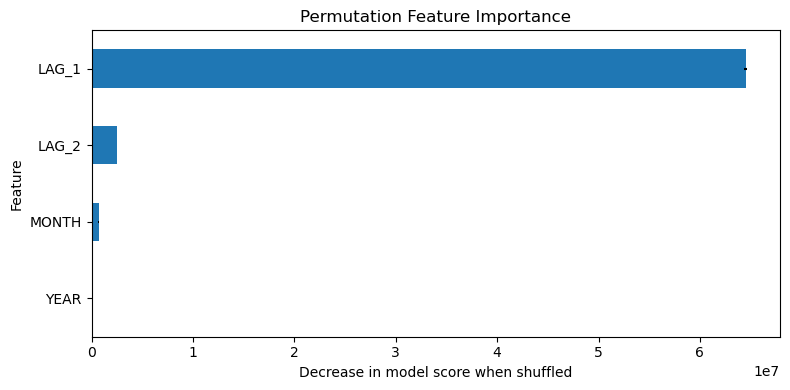

In [24]:
#Permutation importance regression
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": features,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

display(permutation_df.round(4))

permutation_df.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    xerr="Std",
    legend=False,
    figsize=(8, 4)
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in model score when shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

,Actual,Linear Regression,Random Forest
43900,12360726.37,1.093618e+07,1.228173e+07
60604,328434.20,-7.100156e+05,2.233815e+05
51037,8594272.35,6.238433e+06,7.361394e+06
66785,20117039.33,1.560270e+07,1.880083e+07
116725,58670.27,-8.151324e+05,5.940105e+04
120113,170584.03,-8.138258e+05,1.226739e+05
116683,4583012.47,3.473967e+06,4.341098e+06
48396,8966.31,-8.997918e+05,3.640091e+03
138702,6260427.29,4.010205e+06,4.482382e+06
133384,0.00,-9.177606e+05,3.640091e+03


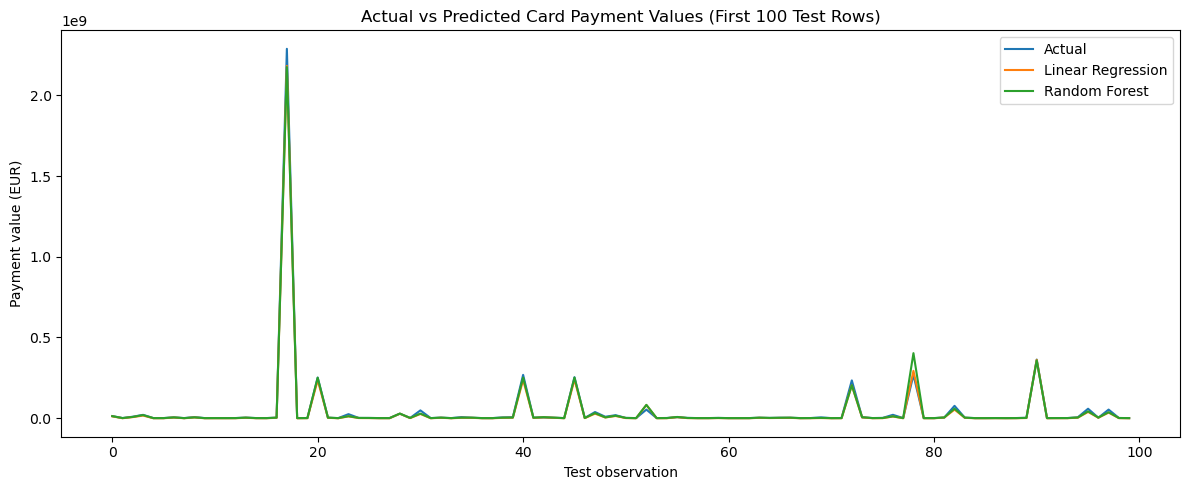

In [ ]:
# Comparing actual and predicted values
comparison_df = pd.DataFrame({
    "Actual": y_test,
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
})

display(comparison_df.head(10))

# Plot a sample of test observations
sample_df = comparison_df.head(100).reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(sample_df["Actual"].values, label="Actual")
plt.plot(sample_df["Linear Regression"].values, label="Linear Regression")
plt.plot(sample_df["Random Forest"].values, label="Random Forest")

plt.title("Actual vs Predicted Card Payment Values (First 100 Test Rows)")
plt.xlabel("Test observation")
plt.ylabel("Payment value (EUR)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Calculating prediction errors
comparison_df["Linear_Error"] = (
    comparison_df["Actual"] - comparison_df["Linear Regression"]
)

comparison_df["RF_Error"] = (
    comparison_df["Actual"] - comparison_df["Random Forest"]
)

print("Linear Regression error summary:")
display(comparison_df["Linear_Error"].describe().round(2))

print("Random Forest error summary:")
display(comparison_df["RF_Error"].describe().round(2))

Linear Regression error summary:


count    1.816100e+04
mean    -3.028312e+05
std      2.743033e+07
min     -8.433656e+08
25%     -6.412196e+05
50%      1.672518e+04
75%      9.177606e+05
max      1.048646e+09
Name: Linear_Error, dtype: float64

Random Forest error summary:


count    1.816100e+04
mean    -6.295614e+05
std      2.572332e+07
min     -6.932365e+08
25%     -1.922847e+05
50%     -3.640090e+03
75%      4.918879e+04
max      8.327701e+08
Name: RF_Error, dtype: float64

In [27]:
# Bootstrap confidence intervals for test MAE
rng = np.random.default_rng(42)
n_bootstrap = 500
n = len(y_test)

linear_mae_boot = []
rf_mae_boot = []

y_test_array = np.asarray(y_test)
linear_pred_array = np.asarray(linear_predictions)
rf_pred_array = np.asarray(rf_predictions)

for _ in range(n_bootstrap):
    indices = rng.integers(0, n, size=n)

    linear_mae_boot.append(
        mean_absolute_error(
            y_test_array[indices],
            linear_pred_array[indices]
        )
    )

    rf_mae_boot.append(
        mean_absolute_error(
            y_test_array[indices],
            rf_pred_array[indices]
        )
    )

print("Linear Regression 95% bootstrap CI for MAE:")
print(np.percentile(linear_mae_boot, [2.5, 97.5]).round(2))

print("Random Forest 95% bootstrap CI for MAE:")
print(np.percentile(rf_mae_boot, [2.5, 97.5]).round(2))

Linear Regression 95% bootstrap CI for MAE:
[3898790.44 4647145.02]
Random Forest 95% bootstrap CI for MAE:
[3389394.03 4119031.29]


In [28]:
# Paired bootstrap comparison of MAE
rng = np.random.default_rng(42)

y_true = np.asarray(y_test)
lin_pred = np.asarray(linear_predictions)
rf_pred = np.asarray(rf_predictions)

mae_difference = []

for _ in range(500):
    indices = rng.integers(0, len(y_true), size=len(y_true))

    linear_boot_mae = mean_absolute_error(
        y_true[indices], lin_pred[indices]
    )
    rf_boot_mae = mean_absolute_error(
        y_true[indices], rf_pred[indices]
    )

    # Positive means Random Forest has lower MAE
    mae_difference.append(linear_boot_mae - rf_boot_mae)

ci = np.percentile(mae_difference, [2.5, 97.5])

print("Mean MAE difference (Linear - Random Forest):",
      round(np.mean(mae_difference), 2))
print("95% bootstrap CI for the difference:",
      ci.round(2))

Mean MAE difference (Linear - Random Forest): 519562.24
95% bootstrap CI for the difference: [372679.62 662294.28]


#Classification Models 

In [29]:
# Create a binary classification dataset
classification_df = model_ready_df.copy()

# 1 = payment increases next month
# 0 = payment stays the same or decreases
classification_df["TARGET_INCREASE"] = (
    classification_df["TARGET_NEXT_VALUE"]
    > classification_df["OBSERVATION"]
).astype(int)

print("Classification dataset shape:", classification_df.shape)

print("\nTarget class counts:")
print(classification_df["TARGET_INCREASE"].value_counts())

print("\nTarget class proportions:")
print(
    classification_df["TARGET_INCREASE"]
    .value_counts(normalize=True)
    .round(3)
)

Classification dataset shape: (76130, 27)

Target class counts:
TARGET_INCREASE
1    39331
0    36799
Name: count, dtype: int64

Target class proportions:
TARGET_INCREASE
1    0.517
0    0.483
Name: proportion, dtype: float64


In [30]:
#Classification Train/Test Split
from sklearn.model_selection import train_test_split

# Sort observations chronologically
classification_df = classification_df.sort_values(
    "REPORTINGPERIOD"
).copy()

# Use the same features as the regression models
features = ["LAG_1", "LAG_2", "YEAR", "MONTH"]
target_class = "TARGET_INCREASE"

# Split chronologically: first 80% of dates for training
dates = sorted(classification_df["REPORTINGPERIOD"].unique())
cutoff_index = int(len(dates) * 0.8)
cutoff_date = dates[cutoff_index]

train_class_df = classification_df[
    classification_df["REPORTINGPERIOD"] < cutoff_date
].copy()

test_class_df = classification_df[
    classification_df["REPORTINGPERIOD"] >= cutoff_date
].copy()

X_train_class = train_class_df[features]
y_train_class = train_class_df[target_class]

X_test_class = test_class_df[features]
y_test_class = test_class_df[target_class]

print("Cutoff date:", cutoff_date)
print("Training rows:", len(X_train_class))
print("Testing rows:", len(X_test_class))
print("\nTraining class proportions:")
print(y_train_class.value_counts(normalize=True).round(3))
print("\nTesting class proportions:")
print(y_test_class.value_counts(normalize=True).round(3))

Cutoff date: 2025-11-30 00:00:00
Training rows: 57969
Testing rows: 18161

Training class proportions:
TARGET_INCREASE
1    0.517
0    0.483
Name: proportion, dtype: float64

Testing class proportions:
TARGET_INCREASE
1    0.517
0    0.483
Name: proportion, dtype: float64


Logistic Regression Results
Accuracy: 0.5188
Precision: 0.518
Recall: 0.9982
F1-score: 0.682

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.01      0.01      8771
           1       0.52      1.00      0.68      9390

    accuracy                           0.52     18161
   macro avg       0.63      0.50      0.35     18161
weighted avg       0.63      0.52      0.36     18161



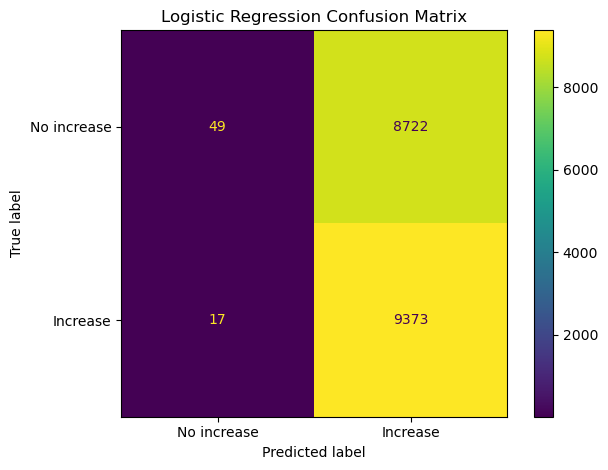

In [31]:
#train Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train the model
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train_class, y_train_class)

# Predict the test set
logistic_predictions = logistic_model.predict(X_test_class)

# Evaluate performance
print("Logistic Regression Results")
print("Accuracy:", round(
    accuracy_score(y_test_class, logistic_predictions), 4
))
print("Precision:", round(
    precision_score(y_test_class, logistic_predictions), 4
))
print("Recall:", round(
    recall_score(y_test_class, logistic_predictions), 4
))
print("F1-score:", round(
    f1_score(y_test_class, logistic_predictions), 4
))

print("\nClassification Report:")
print(classification_report(y_test_class, logistic_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    logistic_predictions,
    display_labels=["No increase", "Increase"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

Scaled Logistic Regression
Accuracy: 0.6288
Precision: 0.6419
Recall: 0.6377
F1-score: 0.6398
              precision    recall  f1-score   support

           0       0.61      0.62      0.62      8771
           1       0.64      0.64      0.64      9390

    accuracy                           0.63     18161
   macro avg       0.63      0.63      0.63     18161
weighted avg       0.63      0.63      0.63     18161



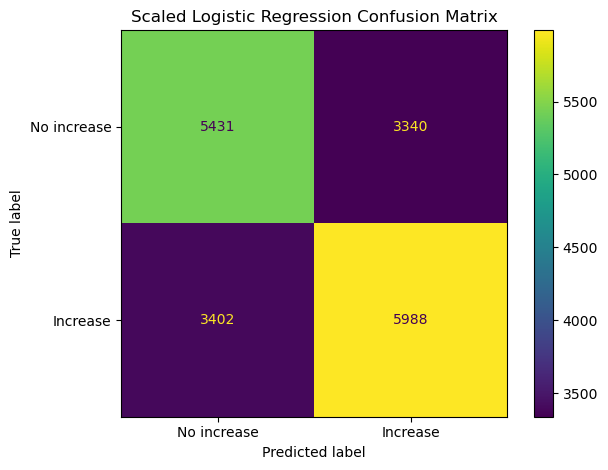

In [32]:
#Scale features using StandardScaler

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

scaled_logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

scaled_logistic_model.fit(X_train_class, y_train_class)

scaled_logistic_predictions = scaled_logistic_model.predict(
    X_test_class
)

print("Scaled Logistic Regression")
print("Accuracy:", round(
    accuracy_score(y_test_class, scaled_logistic_predictions), 4
))
print("Precision:", round(
    precision_score(y_test_class, scaled_logistic_predictions), 4
))
print("Recall:", round(
    recall_score(y_test_class, scaled_logistic_predictions), 4
))
print("F1-score:", round(
    f1_score(y_test_class, scaled_logistic_predictions), 4
))

print(classification_report(
    y_test_class, scaled_logistic_predictions
))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    scaled_logistic_predictions,
    display_labels=["No increase", "Increase"]
)
plt.title("Scaled Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

Random Forest Classifier Results
Accuracy: 0.7013
Precision: 0.6771
Recall: 0.8073
F1-score: 0.7365

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.59      0.66      8771
           1       0.68      0.81      0.74      9390

    accuracy                           0.70     18161
   macro avg       0.71      0.70      0.70     18161
weighted avg       0.71      0.70      0.70     18161



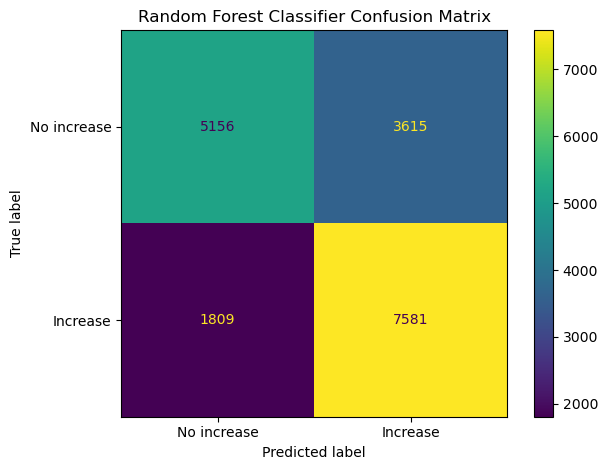

In [33]:
#train Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_classifier.fit(X_train_class, y_train_class)

rf_class_predictions = rf_classifier.predict(X_test_class)

print("Random Forest Classifier Results")
print("Accuracy:", round(
    accuracy_score(y_test_class, rf_class_predictions), 4
))
print("Precision:", round(
    precision_score(y_test_class, rf_class_predictions), 4
))
print("Recall:", round(
    recall_score(y_test_class, rf_class_predictions), 4
))
print("F1-score:", round(
    f1_score(y_test_class, rf_class_predictions), 4
))

print("\nClassification Report:")
print(classification_report(y_test_class, rf_class_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    rf_class_predictions,
    display_labels=["No increase", "Increase"]
)
plt.title("Random Forest Classifier Confusion Matrix")
plt.tight_layout()
plt.show()

In [34]:
#Comparison Table
classification_results = pd.DataFrame({
    "Model": [
        "Scaled Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test_class, scaled_logistic_predictions),
        accuracy_score(y_test_class, rf_class_predictions)
    ],
    "Precision": [
        precision_score(y_test_class, scaled_logistic_predictions),
        precision_score(y_test_class, rf_class_predictions)
    ],
    "Recall": [
        recall_score(y_test_class, scaled_logistic_predictions),
        recall_score(y_test_class, rf_class_predictions)
    ],
    "F1-score": [
        f1_score(y_test_class, scaled_logistic_predictions),
        f1_score(y_test_class, rf_class_predictions)
    ]
})

display(classification_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Scaled Logistic Regression,0.6288,0.6419,0.6377,0.6398
1,Random Forest,0.7013,0.6771,0.8073,0.7365


,Feature,Importance
0,LAG_1,0.3864
1,LAG_2,0.2882
3,MONTH,0.2723
2,YEAR,0.0531


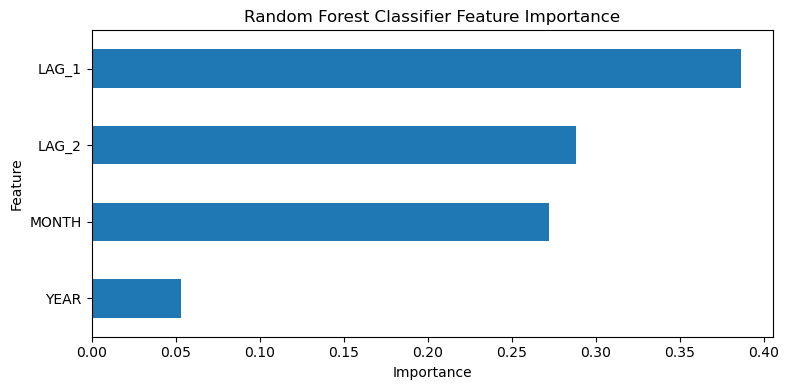

In [35]:
#Classification Feature importance
# Feature importance for the Random Forest classifier
class_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(class_importance_df.round(4))

class_importance_df.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(8, 4)
)

plt.title("Random Forest Classifier Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [36]:
#Permutation importance classification
from sklearn.inspection import permutation_importance

class_perm = permutation_importance(
    rf_classifier,
    X_test_class,
    y_test_class,
    n_repeats=5,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

class_perm_df = pd.DataFrame({
    "Feature": X_test_class.columns,
    "Importance": class_perm.importances_mean,
    "Std": class_perm.importances_std
}).sort_values("Importance", ascending=False)

display(class_perm_df.round(4))

,Feature,Importance,Std
0,LAG_1,0.1495,0.0014
3,MONTH,0.0882,0.0022
1,LAG_2,0.0754,0.0022
2,YEAR,0.0000,0.0000


#Regression Modelling

In [37]:
# Check regression modelling data
print("Regression dataset shape:", model_ready_df.shape)
print("Available features:", ["LAG_1", "LAG_2", "YEAR", "MONTH"])
print("Target: TARGET_NEXT_VALUE")

display(
    model_ready_df[
        [
            "REPORTINGPERIOD",
            "OBSERVATION",
            "LAG_1",
            "LAG_2",
            "YEAR",
            "MONTH",
            "TARGET_NEXT_VALUE"
        ]
    ].head()
)

Regression dataset shape: (76130, 26)
Available features: ['LAG_1', 'LAG_2', 'YEAR', 'MONTH']
Target: TARGET_NEXT_VALUE


,REPORTINGPERIOD,OBSERVATION,LAG_1,LAG_2,YEAR,MONTH,TARGET_NEXT_VALUE
2,2022-12-31,1.761837e+07,19238222.62,17315954.25,2022,12,18152565.81
129780,2022-12-31,1.034041e+08,76657585.25,66554750.90,2022,12,47043404.38
85362,2022-12-31,1.375181e+06,831124.33,811557.82,2022,12,810371.30
85409,2022-12-31,1.305365e+06,1606078.69,2663828.75,2022,12,1511019.22
129733,2022-12-31,3.764451e+06,4121555.25,3673819.41,2022,12,3619456.51


In [38]:
# Chronological train/test split for regression

model_ready_df = model_ready_df.sort_values(
    "REPORTINGPERIOD"
).copy()

features = ["LAG_1", "LAG_2", "YEAR", "MONTH"]
target = "TARGET_NEXT_VALUE"

# Use the earliest 80% of dates for training
dates = sorted(model_ready_df["REPORTINGPERIOD"].unique())
cutoff_index = int(len(dates) * 0.8)
cutoff_date = dates[cutoff_index]

# Keep training targets strictly before the test period
target_month = (
    model_ready_df["REPORTINGPERIOD"] +
    pd.DateOffset(months=1)
)

train_df = model_ready_df.loc[
    target_month < cutoff_date
].copy()

test_df = model_ready_df.loc[
    model_ready_df["REPORTINGPERIOD"] >= cutoff_date
].copy()

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Cutoff date:", cutoff_date)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_df["REPORTINGPERIOD"].min(),
      "to", train_df["REPORTINGPERIOD"].max())
print("Testing period:", test_df["REPORTINGPERIOD"].min(),
      "to", test_df["REPORTINGPERIOD"].max())

Cutoff date: 2025-11-30 00:00:00
Training rows: 57969
Testing rows: 18161
Training period: 2022-12-31 00:00:00 to 2025-09-30 00:00:00
Testing period: 2025-11-30 00:00:00 to 2026-07-31 00:00:00


In [ ]:
# Regression baseline
# predicting the training-set mean

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Regression Baseline Results")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))
print("R²:", round(baseline_r2, 4))

Regression Baseline Results
MAE: 58996759.74
RMSE: 231286803.85
R²: -0.0004


In [40]:
from sklearn.linear_model import LinearRegression

# Train Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict test values
linear_predictions = linear_model.predict(X_test)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²:", round(linear_r2, 4))

Linear Regression Results
MAE: 4288350.69
RMSE: 27431245.13
R²: 0.9859


In [41]:
from sklearn.ensemble import RandomForestRegressor

# Train Random Forest Regression
rf_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_regressor.fit(X_train, y_train)

# Predict test values
rf_predictions = rf_regressor.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 4))

Random Forest Regression Results
MAE: 3778163.32
RMSE: 25806144.68
R²: 0.9875


In [42]:
#Comparison table
regression_results = pd.DataFrame({
    "Model": [
        "Baseline (Mean)",
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        rf_r2
    ]
})

display(regression_results.round(4))

,Model,MAE,RMSE,R2
0,Baseline (Mean),5.899676e+07,2.312868e+08,-0.0004
1,Linear Regression,4.288351e+06,2.743125e+07,0.9859
2,Random Forest Regression,3.778163e+06,2.580614e+07,0.9875


,Feature,Importance
0,LAG_1,0.8912
1,LAG_2,0.1055
3,MONTH,0.0028
2,YEAR,0.0006


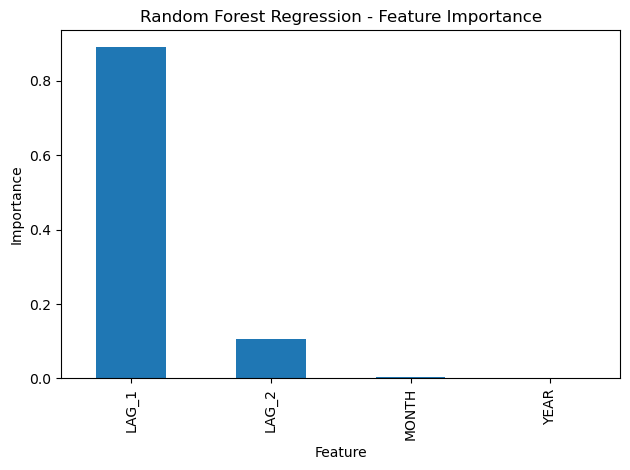

In [43]:
# Feature importance for Random Forest Regression
regression_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_regressor.feature_importances_
}).sort_values("Importance", ascending=False)

display(regression_importance.round(4))

# Plot feature importance
regression_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    title="Random Forest Regression - Feature Importance"
)

plt.ylabel("Importance")
plt.xlabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
#permutation importance from regression
from sklearn.inspection import permutation_importance

reg_perm = permutation_importance(
    rf_regressor,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

reg_perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": reg_perm.importances_mean,
    "Std": reg_perm.importances_std
}).sort_values("Importance", ascending=False)

display(reg_perm_df.round(4))

,Feature,Importance,Std
0,LAG_1,6.315167e+07,223353.9021
1,LAG_2,3.489996e+06,30432.2592
3,MONTH,6.846812e+05,31476.8619
2,YEAR,0.000000e+00,0.0000


In [45]:
regression_results.to_csv(
    "regression_model_comparison.csv",
    index=False
)

print("Regression comparison saved successfully.")

Regression comparison saved successfully.


In [46]:
# Check that every target is from the immediately following calendar month
check_df = model_ready_df.copy()

check_df["EXPECTED_TARGET_MONTH"] = (
    check_df["REPORTINGPERIOD"] + pd.DateOffset(months=1)
)

# Rebuild the actual next-month target for verification
future_check = model_df[
    ["SERIES_KEY", "REPORTINGPERIOD", "OBSERVATION"]
].copy()

future_check["REPORTINGPERIOD"] = (
    future_check["REPORTINGPERIOD"] - pd.DateOffset(months=1)
)

future_check = future_check.rename(
    columns={
        "OBSERVATION": "VERIFIED_TARGET",
        "REPORTINGPERIOD": "FEATURE_MONTH"
    }
)

check_df = check_df.merge(
    future_check,
    left_on=["SERIES_KEY", "REPORTINGPERIOD"],
    right_on=["SERIES_KEY", "FEATURE_MONTH"],
    how="left",
    validate="one_to_one"
)

print(
    "Targets matching the next calendar month:",
    check_df["TARGET_NEXT_VALUE"].eq(
        check_df["VERIFIED_TARGET"]
    ).all()
)

print("Rows checked:", len(check_df))

Targets matching the next calendar month: True
Rows checked: 76130


In [47]:
# Find the month each row is predicting
train_target_months = (
    train_df["REPORTINGPERIOD"] + pd.DateOffset(months=1)
)

test_target_months = (
    test_df["REPORTINGPERIOD"] + pd.DateOffset(months=1)
)

print("Latest training target month:", train_target_months.max())
print("Earliest testing target month:", test_target_months.min())

print(
    "Target months overlap:",
    train_target_months.max() >= test_target_months.min()
)

Latest training target month: 2025-10-30 00:00:00
Earliest testing target month: 2025-12-30 00:00:00
Target months overlap: False


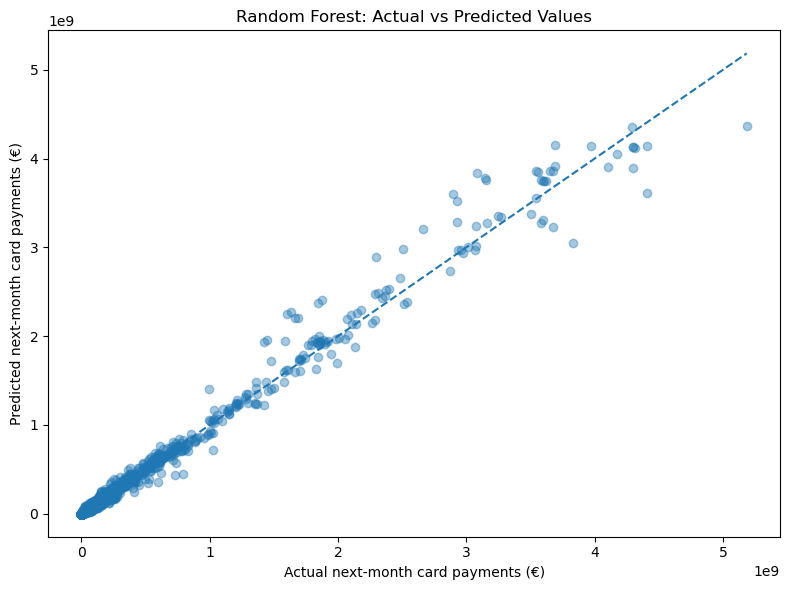

In [48]:
#Prediction versus Actual plot
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.4)

min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual next-month card payments (€)")
plt.ylabel("Predicted next-month card payments (€)")
plt.title("Random Forest: Actual vs Predicted Values")
plt.tight_layout()
plt.show()

#Bootsrap Confidence Intervals


In [49]:

from sklearn.utils import resample
import numpy as np
import pandas as pd

# Actual values and predictions from the three models
predictions = {
    "Baseline (Mean)": baseline_predictions,
    "Linear Regression": linear_predictions,
    "Random Forest Regression": rf_predictions
}

bootstrap_results = []

for model_name, predicted in predictions.items():
    errors = np.abs(np.asarray(y_test) - np.asarray(predicted))
    bootstrap_mae = []

    for i in range(1000):
        sample_errors = resample(
            errors,
            replace=True,
            random_state=42 + i
        )
        bootstrap_mae.append(sample_errors.mean())

    lower = np.percentile(bootstrap_mae, 2.5)
    upper = np.percentile(bootstrap_mae, 97.5)

    bootstrap_results.append({
        "Model": model_name,
        "Test MAE": errors.mean(),
        "95% CI Lower": lower,
        "95% CI Upper": upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(2))


,Model,Test MAE,95% CI Lower,95% CI Upper
0,Baseline (Mean),58996759.74,55793826.97,62268747.32
1,Linear Regression,4288350.69,3893332.90,4690577.39
2,Random Forest Regression,3778163.32,3409573.19,4146193.82
